# Chapter 2 · Rotations

**Companion notebook to *Mathematics for Robotics: A Beginner's Guide*** · ROSFORGE · rosforge.com

Read Chapter 2 of the book, then run each cell here to see the idea at work. Change the numbers and re-run: that is the fastest way to build intuition. Section numbers below match the book.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
np.set_printoptions(precision=3, suppress=True)
deg = np.pi / 180

def R2(a):
    c, s = np.cos(a), np.sin(a); return np.array([[c, -s], [s, c]])
def Rx(a):
    c, s = np.cos(a), np.sin(a); return np.array([[1, 0, 0], [0, c, -s], [0, s, c]])
def Ry(a):
    c, s = np.cos(a), np.sin(a); return np.array([[c, 0, s], [0, 1, 0], [-s, 0, c]])
def Rz(a):
    c, s = np.cos(a), np.sin(a); return np.array([[c, -s, 0], [s, c, 0], [0, 0, 1]])

def draw_frame(ax, R, origin=(0, 0, 0), scale=1.0, label=""):
    # a coordinate frame = three arrows (x red, y green, z blue): the COLUMNS of R
    for col, c in zip(R.T, ["r", "g", "b"]):
        ax.quiver(*origin, *(scale * col), color=c, lw=3)
    if label: ax.text(*(np.array(origin) + scale * 1.1), label)

def frame_axes(ax, lim=1.3):
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_zlim(-lim, lim)
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z")

## 2.1 Rotation in the plane
$R(a)=\begin{bmatrix}\cos a&-\sin a\\\sin a&\cos a\end{bmatrix}$. Its columns are the images of $e_1$ and $e_2$. Planar rotations commute and their angles add.

R(60 deg) =
 [[ 0.5   -0.866]
 [ 0.866  0.5  ]]
(1,0) goes to [0.5   0.866]    length still 1.0
R(b)R(a) == R(a+b): True
order does not matter in 2D: True


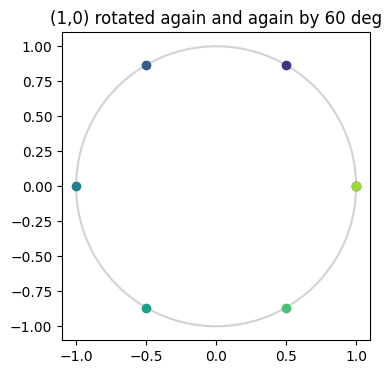

In [2]:
a = 60 * deg
print("R(60 deg) =\n", R2(a))
print("(1,0) goes to", R2(a) @ [1, 0], "   length still", np.linalg.norm(R2(a) @ [1, 0]))
print("R(b)R(a) == R(a+b):", np.allclose(R2(0.4) @ R2(0.9), R2(1.3)))
print("order does not matter in 2D:", np.allclose(R2(0.4) @ R2(0.9), R2(0.9) @ R2(0.4)))

# TRY IT: change `a` and watch a point move around the circle
t = np.linspace(0, 2*np.pi, 100)
plt.figure(figsize=(4, 4)); plt.plot(np.cos(t), np.sin(t), color="lightgrey")
for k in range(7):
    p = R2(k * a) @ [1, 0]; plt.plot(*p, "o", color=plt.cm.viridis(k / 7))
plt.gca().set_aspect("equal"); plt.title("(1,0) rotated again and again by 60 deg"); plt.show()

## 2.2 Rotations in space
The three elementary rotations spin about the $x$-, $y$- or $z$-axis. **The columns of a rotation matrix are the axes of the rotated frame.**

Rz(90 deg) =
 [[ 0. -1.  0.]
 [ 1.  0.  0.]
 [ 0.  0.  1.]]
new x-axis (column 1): [0. 1. 0.]   new y-axis (column 2): [-1.  0.  0.]


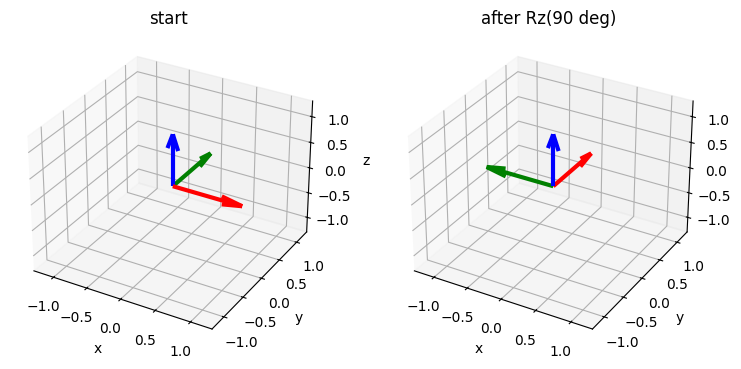

In [3]:
R = Rz(90 * deg)
print("Rz(90 deg) =\n", R)
print("new x-axis (column 1):", R[:, 0], "  new y-axis (column 2):", R[:, 1])

fig = plt.figure(figsize=(9, 4.5))
for i, (name, M) in enumerate([("start", np.eye(3)), ("after Rz(90 deg)", Rz(90 * deg))]):
    ax = fig.add_subplot(1, 2, i + 1, projection="3d"); draw_frame(ax, M); frame_axes(ax); ax.set_title(name)
plt.show()

## 2.3 In space, the order of rotations matters

Rx then Rz commute? False


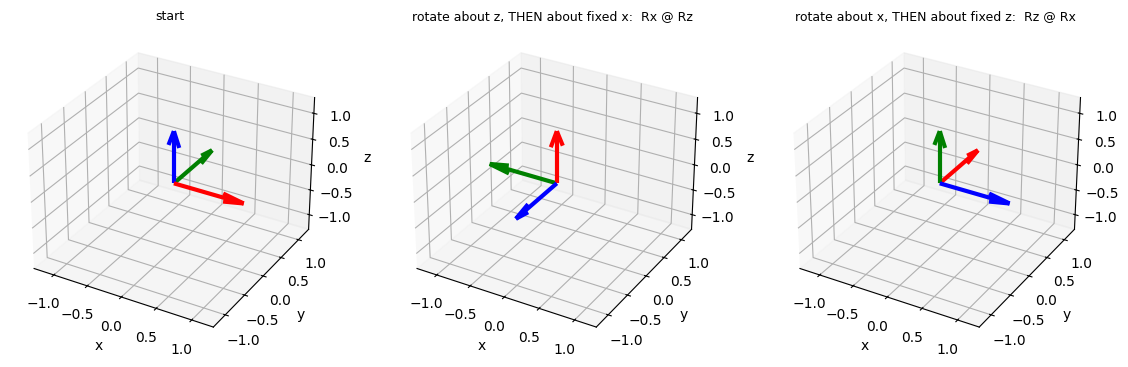

In [4]:
A, B = Rx(90 * deg), Rz(90 * deg)
print("Rx then Rz commute?", np.allclose(A @ B, B @ A))

fig = plt.figure(figsize=(14, 4.5))
for i, (name, M) in enumerate([("start", np.eye(3)), ("rotate about z, THEN about fixed x:  Rx @ Rz", A @ B), ("rotate about x, THEN about fixed z:  Rz @ Rx", B @ A)]):
    ax = fig.add_subplot(1, 3, i + 1, projection="3d"); draw_frame(ax, M); frame_axes(ax); ax.set_title(name, fontsize=9)
plt.show()

## 2.4 Euler angles and fixed angles, and gimbal lock
Moving axes multiply on the **right**; fixed axes multiply on the **left**; the same three angles give the same matrix $R_z(\gamma)R_y(\beta)R_x(\alpha)$ read both ways. At $\beta=90^\circ$ two axes line up and a degree of freedom is lost.

In [5]:
a, b, c = 0.5, -0.3, 1.1

R_fixed = np.eye(3)
for Rstep in [Rx(a), Ry(b), Rz(c)]:      # fixed axes: multiply on the LEFT
    R_fixed = Rstep @ R_fixed

R_euler = np.eye(3)
for Rstep in [Rz(c), Ry(b), Rx(a)]:      # moving axes: multiply on the RIGHT
    R_euler = R_euler @ Rstep

print("fixed X-Y-Z(a,b,c) == Euler Z-Y-X(c,b,a):", np.allclose(R_fixed, R_euler))
print(R_fixed)

fixed X-Y-Z(a,b,c) == Euler Z-Y-X(c,b,a): True
[[ 0.433 -0.846  0.31 ]
 [ 0.851  0.272 -0.449]
 [ 0.296  0.458  0.838]]


In [6]:
def euler_zyx(alpha, beta, gamma):         # Rz(alpha) Ry(beta) Rx(gamma)
    return Rz(alpha) @ Ry(beta) @ Rx(gamma)

R1 = euler_zyx(30 * deg, 90 * deg, 10 * deg)
R2_ = euler_zyx(50 * deg, 90 * deg, 30 * deg)          # both outer angles shifted by +20 deg
print("two different angle triples, same rotation at beta = 90 deg:", np.allclose(R1, R2_))
print("away from 90 deg this does not happen:", not np.allclose(euler_zyx(30*deg, 20*deg, 10*deg), euler_zyx(50*deg, 20*deg, 30*deg)))

two different angle triples, same rotation at beta = 90 deg: True
away from 90 deg this does not happen: True


## 2.5 Axis and angle (Rodrigues' formula)
$R=I+\sin\theta\,K+(1-\cos\theta)K^2$, with $K$ the cross-product matrix of the unit axis. Going back: $\theta=\arccos\frac{\operatorname{tr}R-1}{2}$, and the axis comes from the antisymmetric part of $R$.

In [7]:
def skew(k):
    x, y, z = k
    return np.array([[0, -z, y], [z, 0, -x], [-y, x, 0]])

def axis_angle_to_R(k, theta):
    k = np.asarray(k, float); k = k / np.linalg.norm(k); K = skew(k)
    return np.eye(3) + np.sin(theta) * K + (1 - np.cos(theta)) * K @ K

def R_to_axis_angle(R):
    theta = np.arccos(np.clip((np.trace(R) - 1) / 2, -1, 1))
    if np.isclose(np.sin(theta), 0):
        return None, theta                  # 0 or 180 deg: the simple formula breaks (axis needs special handling)
    k = np.array([R[2, 1] - R[1, 2], R[0, 2] - R[2, 0], R[1, 0] - R[0, 1]]) / (2 * np.sin(theta))
    return k, theta

print("axis z, 90 deg  equals Rz(90 deg):", np.allclose(axis_angle_to_R([0, 0, 1], 90 * deg), Rz(90 * deg)))
R = axis_angle_to_R([1, 2, 2], 70 * deg)
k, theta = R_to_axis_angle(R)
print("recovered axis:", k, "(should be (1,2,2)/3 =", np.array([1, 2, 2]) / 3, ")   angle:", theta / deg, "deg")

axis z, 90 deg  equals Rz(90 deg): True
recovered axis: [0.333 0.667 0.667] (should be (1,2,2)/3 = [0.333 0.667 0.667] )   angle: 69.99999999999999 deg


In [8]:
# the cross product as a matrix, and the identity K^2 = k k^T - I (for a unit vector k)
rng = np.random.default_rng(4); k = rng.normal(size=3); k /= np.linalg.norm(k); u = rng.normal(size=3)
print("K u == k x u :", np.allclose(skew(k) @ u, np.cross(k, u)))
print("K^2 == k k^T - I :", np.allclose(skew(k) @ skew(k), np.outer(k, k) - np.eye(3)))

# the book's worked example: the cyclic permutation matrix is a 120 degree rotation about (1,1,1)
Rc = np.array([[0, 0, 1], [1, 0, 0], [0, 1, 0.]])
k, th = R_to_axis_angle(Rc); print("axis:", k, "(= (1,1,1)/sqrt(3) =", np.ones(3) / np.sqrt(3), ")   angle:", th / deg, "deg")

K u == k x u : True
K^2 == k k^T - I : True
axis: [0.577 0.577 0.577] (= (1,1,1)/sqrt(3) = [0.577 0.577 0.577] )   angle: 120.00000000000001 deg


## 2.6 Quaternions
$(x,y,z,w)=(\hat k\sin\frac\theta2,\cos\frac\theta2)$. There is no gimbal lock; $q$ and $-q$ are the same rotation (the *double cover*), and quaternion multiplication composes rotations.

In [9]:
def quat_from_axis_angle(k, theta):
    k = np.asarray(k, float); k = k / np.linalg.norm(k)
    return np.concatenate([k * np.sin(theta / 2), [np.cos(theta / 2)]])      # (x, y, z, w)

def quat_to_R(q):
    K = skew(q[:3]); w = q[3]
    return np.eye(3) + 2 * w * K + 2 * K @ K

def quat_mul(q2, q1):                                                         # q1 first, then q2
    x1, y1, z1, w1 = q1; x2, y2, z2, w2 = q2
    return np.array([w2*x1 + x2*w1 + y2*z1 - z2*y1, w2*y1 - x2*z1 + y2*w1 + z2*x1,
                     w2*z1 + x2*y1 - y2*x1 + z2*w1, w2*w1 - x2*x1 - y2*y1 - z2*z1])

q = quat_from_axis_angle([0, 0, 1], 90 * deg)
print("90 deg about z  ->  quaternion", q, "  (sqrt(2)/2 =", np.sqrt(2)/2, ")")
print("quaternion -> matrix equals Rz(90):", np.allclose(quat_to_R(q), Rz(90 * deg)))
print("q and -q same rotation:", np.allclose(quat_to_R(q), quat_to_R(-q)))

# composing two rotations: multiply quaternions OR multiply matrices - same answer
qa = quat_from_axis_angle([1, 0, 0], 40 * deg); qb = quat_from_axis_angle([0, 1, 1], -70 * deg)
print("quaternion product matches matrix product:", np.allclose(quat_to_R(quat_mul(qb, qa)), quat_to_R(qb) @ quat_to_R(qa)))

90 deg about z  ->  quaternion [0.    0.    0.707 0.707]   (sqrt(2)/2 = 0.7071067811865476 )
quaternion -> matrix equals Rz(90): True
q and -q same rotation: True
quaternion product matches matrix product: True


In [10]:
# the book's example: two quarter turns about z make a half turn
s = np.sqrt(2) / 2; q = np.array([0, 0, s, s])
print("q * q =", quat_mul(q, q).round(6), "  (a 180 degree rotation about z has quaternion (0,0,1,0))")

# double cover: after one full turn (360 deg) the rotation is back, but the quaternion is -1
print("quaternion after 360 deg:", quat_from_axis_angle([0, 0, 1], 2*np.pi).round(6), "   rotation matrix is the identity:", np.allclose(quat_to_R(quat_from_axis_angle([0, 0, 1], 2*np.pi)), np.eye(3)))

q * q = [0. 0. 1. 0.]   (a 180 degree rotation about z has quaternion (0,0,1,0))
quaternion after 360 deg: [ 0.  0.  0. -1.]    rotation matrix is the identity: True


## 2.7 Interpolating between rotations (SLERP)
Averaging two rotation matrices does not give a rotation. Interpolate the *angle* instead: SLERP moves along the arc between two quaternions at constant angular speed.

average of two rotations is a rotation? False (no)


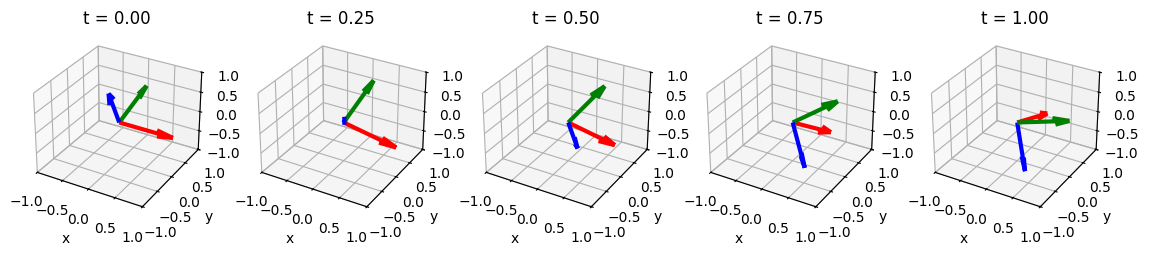

In [11]:
def slerp(q0, q1, t):
    c = q0 @ q1
    if c < 0: q1, c = -q1, -c                  # take the short way round (q and -q are the same rotation)
    Om = np.arccos(np.clip(c, -1, 1))
    if Om < 1e-8: return q0
    return (np.sin((1 - t) * Om) * q0 + np.sin(t * Om) * q1) / np.sin(Om)

R0, R1 = np.eye(3), Rz(180 * deg)
print("average of two rotations is a rotation?", np.allclose(((R0 + R1) / 2).T @ ((R0 + R1) / 2), np.eye(3)), "(no)")

q_start = quat_from_axis_angle([1, 0, 0], 20 * deg); q_end = quat_from_axis_angle([1, 1, 0], 150 * deg)
fig = plt.figure(figsize=(14, 3.5))
for i, t in enumerate(np.linspace(0, 1, 5)):
    ax = fig.add_subplot(1, 5, i + 1, projection="3d"); draw_frame(ax, quat_to_R(slerp(q_start, q_end, t)), scale=1); frame_axes(ax, 1); ax.set_title(f"t = {t:.2f}")
plt.show()

In [12]:
# on the unit circle: blending the angle vs blending the coordinates (the book's example, t = 1/3)
t = 1/3
p_angle = np.array([np.cos(t * 90 * deg), np.sin(t * 90 * deg)])
blend = (1 - t) * np.array([1, 0]) + t * np.array([0, 1]); p_coord = blend / np.linalg.norm(blend)
print("blend the angle      :", p_angle.round(3)); print("blend the coordinates:", p_coord.round(3), " (close, not equal)")

blend the angle      : [0.866 0.5  ]
blend the coordinates: [0.894 0.447]  (close, not equal)


---
## Exercises

> **Exercise 2.1**
>
> Compute $R(90^\circ)(2,0)$ and $R(45^\circ)R(45^\circ)(2,0)$. Why do they agree?

In [13]:
# Your work here (try the exercise before looking at the solution cell below)

**Solution 2.1** *(this is the book's Appendix B, checked in code)*

In [14]:
a = R2(90*deg) @ [2, 0]; b = R2(45*deg) @ R2(45*deg) @ [2, 0]; print(a.round(6), b.round(6)); assert np.allclose(a, [0, 2]) and np.allclose(a, b)
print("planar rotation angles add")

[0. 2.] [0. 2.]
planar rotation angles add


> **Exercise 2.2**
>
> Compute $R_z(90^\circ)R_x(90^\circ)e_3$ and $R_x(90^\circ)R_z(90^\circ)e_3$.

In [15]:
# Your work here (try the exercise before looking at the solution cell below)

**Solution 2.2** *(this is the book's Appendix B, checked in code)*

In [16]:
e3 = np.array([0, 0, 1.]); p = Rz(90*deg) @ Rx(90*deg) @ e3; q_ = Rx(90*deg) @ Rz(90*deg) @ e3
print(p.round(6), q_.round(6)); assert np.allclose(p, [1, 0, 0]) and np.allclose(q_, [0, -1, 0])
print("they differ: order matters in 3D")

[ 1. -0.  0.] [ 0. -1.  0.]
they differ: order matters in 3D


> **Exercise 2.3**
>
> Use the vector form of Rodrigues' formula to rotate $v=(1,0,0)$ by $90^\circ$ about $\hat k=(0,0,1)$.

In [17]:
# Your work here (try the exercise before looking at the solution cell below)

**Solution 2.3** *(this is the book's Appendix B, checked in code)*

In [18]:
v = np.array([1., 0, 0]); k = np.array([0., 0, 1]); th = 90*deg
out = v*np.cos(th) + np.cross(k, v)*np.sin(th) + k*(k @ v)*(1 - np.cos(th)); print(out.round(6)); assert np.allclose(out, [0, 1, 0])

[0. 1. 0.]


> **Exercise 2.4**
>
> Find the axis and angle of $R=\begin{bmatrix}0&-1&0\\1&0&0\\0&0&1\end{bmatrix}$.

In [19]:
# Your work here (try the exercise before looking at the solution cell below)

**Solution 2.4** *(this is the book's Appendix B, checked in code)*

In [20]:
k, th = R_to_axis_angle(np.array([[0, -1, 0], [1, 0, 0], [0, 0, 1.]])); print(k.round(6), th / deg); assert np.allclose(k, [0, 0, 1]) and np.isclose(th / deg, 90)

[0. 0. 1.] 90.0


> **Exercise 2.5**
>
> Give the unit quaternions for (a) $90^\circ$ about $y$ and (b) $180^\circ$ about $x$.

In [21]:
# Your work here (try the exercise before looking at the solution cell below)

**Solution 2.5** *(this is the book's Appendix B, checked in code)*

In [22]:
qa = quat_from_axis_angle([0, 1, 0], 90*deg); qb = quat_from_axis_angle([1, 0, 0], 180*deg); print(qa.round(4), qb.round(4))
assert np.allclose(qa, [0, np.sqrt(2)/2, 0, np.sqrt(2)/2]) and np.allclose(qb, [1, 0, 0, 0])

[0.    0.707 0.    0.707] [1. 0. 0. 0.]


> **Exercise 2.6**
>
> Show that $R_z(\gamma)R_y(90^\circ)R_x(\alpha)$ is unchanged when $\alpha$ and $\gamma$ both increase by $30^\circ$.

In [23]:
# Your work here (try the exercise before looking at the solution cell below)

**Solution 2.6** *(this is the book's Appendix B, checked in code)*

In [24]:
R1 = euler_zyx(0.3, 90*deg, 0.8); R2_ = euler_zyx(0.3 + 30*deg, 90*deg, 0.8 + 30*deg); print(np.allclose(R1, R2_)); assert np.allclose(R1, R2_)
print("the matrix depends only on the difference of the two angles")

True
the matrix depends only on the difference of the two angles


---
**Next:** `03_Frames_and_Transforms.ipynb` (Chapter 3)

*Mathematics for Robotics: A Beginner's Guide* · ROSFORGE · rosforge.com